# 05 MECÂNICA DA ZONA DE ATERRAMENTO, FLEXÃO ELÁSTICA DE MARÉ, COMPLEMENTO DE SCHUR LAGRANGIANO E ANÁLISE DE IDENTIFICABILIDADE (FISHER)

Este caderno desenvolve a teoria física e os resultados observacionais para a **Zona de Aterramento (*Grounding Zone* — GZ)** das plataformas de gelo do Mar de Amundsen (Thwaites, Pine Island, Crosson, Dotson e Cosgrove):
1. **Revisão crítica da literatura da zona de aterramento e flexão de maré na Antártica Ocidental:** Holdsworth (1969), Vaughan (1995), Schmeltz et al. (2002), Fricker et al. (2009), Walker et al. (2013), Wild et al. (2019, 2022, 2024), Milillo et al. (2019, 2022), Freer et al. (2023), Ciracì et al. (2023), Rignot et al. (2024), Chartrand et al. (2024), Meng et al. (2025) e Hendley Elgart (2026);
2. **Equação diferencial de 4ª ordem da viga elástica sobre fundação fluida (`thwaites.flexure.beam`):** dedução do perfil de amortecimento de maré $\beta(x)$, número de onda flexural $\lambda$ e rigidez efetiva $D(x) = E^* H(x)^3 / [12(1 - \nu^2)]$;
3. **Triagem geométrica trilha ICESat-2 $\times$ vetor velocidade ITS_LIVE (`triagem_geometria_flexao.py`):** por que a Thwaites tem a melhor geometria orbital da ASE ($10^\circ$ de ângulo mediano trilha–fluxo, $71\%$ de trechos aptos), mas escoamento rápido ($> 1.000\text{ m/ano}$) que inviabiliza o ajuste Euleriano;
4. **Solução conjunta exata da resposta à maré $\beta$ com topografia móvel Lagrangiana via Complemento de Schur e erro sanduíche CR1 (`run_tide_response_lagrangian.py`):** redução do RMS na Thwaites de $1{,}41\text{ m}$ para $0{,}78\text{ m}$ ($38{,}1\text{ milhões}$ de segmentos em $65.500$ células de $500\text{ m}$) e determinação empírica da largura da zona de flexão $d^* \in [1{,}5;\; 3{,}5]\text{ km}$;
5. **Teoria de Identificabilidade e Matriz de Informação de Fisher (`flexure_f3_synthetic.py`):** demonstração matemática e numérica de por que a inversão de flexão por maré com o ruído do ATL06 determina apenas o comprimento de onda flexural $\lambda$ (autovalores relativos de Fisher $1 : 10^{-2} : 10^{-7} : 0$), não permitindo separar $E^*$ de $H(x)$ nem recuperar o gradiente de espessura sem radar aerotransportado independente.

---

## 1. Formulação Física da Flexão Elástica de Maré e Literatura da Zona de Aterramento

A transição entre o manto de gelo apoiado no substrato rochoso e a plataforma de gelo em flutuação livre não é uma linha geométrica, mas sim uma **zona de aterramento (*Grounding Zone* — GZ)** de vários quilômetros de largura (Fricker et al., 2009; Rignot et al., 2024), composta por:
- **Ponto $G$ (*Grounding Line* / limite interno de flexão):** ponto mais a montante onde a superfície responde à oscilação vertical da maré oceânica $\eta_m(t)$;
- **Zona de migração de maré e intrusão de água marinha:** faixa onde a linha de aterramento migra horizontalmente entre maré baixa e maré alta e onde água oceânica pressurizada penetra em cavidades subglaciais quilométricas na maré de sizígia (até $15\text{ km}$ em planícies de gelo rasas segundo Freer et al., 2023, *The Cryosphere*; e $2\text{ a }6\text{ km}$ na Thwaites segundo Rignot et al., 2024, *PNAS*, e Milillo et al., 2019, 2022);
- **Ponto $H$ (*Hydrostatic Point* / distância $d^*$):** limite a jusante a partir do qual as tensões elásticas e viscoelásticas de flexão decaem a zero e a coluna de gelo passa a satisfazer o equilíbrio hidrostático livre de Arquimedes ($\beta(x) \to 1$).

### 1.1 Equação da Viga Elástica de Rigidez Variável sobre Fundação de Winkler (`thwaites.flexure.beam`)
Modelando a plataforma ao longo da coordenada longitudinal de fluxo $x \ge 0$ (com origem em $G$) como uma placa/viga elástica de espessura variável $H(x)$, módulo de Young efetivo $E^*$ e razão de Poisson $\nu = 0{,}3$ submetida ao empuxo hidrostático da água do mar de densidade $\rho_w = 1027\text{ kg m}^{-3}$ sob deslocamento de maré $A = \eta_m(t)$ (Holdsworth, 1969; Vaughan, 1995; Schmeltz et al., 2002; Walker et al., 2013; Wild et al., 2019; Hendley Elgart, 2026):

$$\frac{d^2}{dx^2}\left(D(x)\frac{d^2 w}{dx^2}\right) + \rho_w g \left(w(x) - A\right) = 0, \qquad D(x) = \frac{E^* H(x)^3}{12(1 - \nu^2)}$$

com condições de contorno de engaste no limite apoiado ($w(0) = 0,\; w'(0) = 0$) e flutuação livre no oceano ($w(L) = A,\; w'(L) = 0$). Pela linearidade em $A$, a razão adimensional de resposta à maré $\beta(x) \equiv w(x)/A$ satisfaz a EDO com $A = 1$. Para espessura uniforme $H_0$ ($D(x) \equiv D_0$), a solução analítica fechada de Vaughan (1995) é:

$$\beta(x) = 1 - e^{-x / \lambda}\left[\cos\left(\frac{x}{\lambda}\right) + \sin\left(\frac{x}{\lambda}\right)\right], \qquad \lambda = \left(\frac{4 D_0}{\rho_w g}\right)^{1/4} = \left(\frac{E^* H_0^3}{3(1 - \nu^2)\rho_w g}\right)^{1/4}$$

Notavelmente, $\beta(x)$ ultrapassa ligeiramente $1$ no primeiro máximo flexural em $x = \frac{3\pi}{4}\lambda$ ($\beta_{\max} = 1 + e^{-3\pi/4} \approx 1{,}094$) antes de amortecer para $1{,}0$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from thwaites.flexure.beam import beta_analytic_uniform, beta_profile, hermite, rigidity

# Triagem geométrica medida na ASE (trilha ICESat-2 × fluxo ITS_LIVE × linha de aterramento InSAR v2.1)
triagem_df = pd.DataFrame([
    {"Plataforma": "Thwaites", "Ângulo Mediano Trilha–Fluxo (°)": 10.0, "Trilhas a < 30° do Fluxo (%)": 91.0, "Fração Confinada 3–15 km (%)": 24.0, "Fração Apta (< 30° e Livre) (%)": 71.0, "Apta e Lenta (< 1.000 m/ano) (%)": 35.0},
    {"Plataforma": "Crosson", "Ângulo Mediano Trilha–Fluxo (°)": 38.0, "Trilhas a < 30° do Fluxo (%)": 43.0, "Fração Confinada 3–15 km (%)": 20.0, "Fração Apta (< 30° e Livre) (%)": 34.0, "Apta e Lenta (< 1.000 m/ano) (%)": 34.0},
    {"Plataforma": "Cosgrove", "Ângulo Mediano Trilha–Fluxo (°)": 46.0, "Trilhas a < 30° do Fluxo (°)": 33.0, "Fração Confinada 3–15 km (%)": 8.0, "Fração Apta (< 30° e Livre) (%)": 31.0, "Apta e Lenta (< 1.000 m/ano) (%)": 31.0},
    {"Plataforma": "Dotson", "Ângulo Mediano Trilha–Fluxo (°)": 54.0, "Trilhas a < 30° do Fluxo (%)": 26.0, "Fração Confinada 3–15 km (%)": 17.0, "Fração Apta (< 30° e Livre) (%)": 23.0, "Apta e Lenta (< 1.000 m/ano) (%)": 23.0},
    {"Plataforma": "Pine Island", "Ângulo Mediano Trilha–Fluxo (°)": 54.0, "Trilhas a < 30° do Fluxo (%)": 19.0, "Fração Confinada 3–15 km (%)": 13.0, "Fração Apta (< 30° e Livre) (%)": 18.0, "Apta e Lenta (< 1.000 m/ano) (%)": 18.0},
]).set_index("Plataforma")
triagem_df

,Ângulo Mediano Trilha–Fluxo (°),Trilhas a < 30° do Fluxo (%),Fração Confinada 3–15 km (%),Fração Apta (< 30° e Livre) (%),Apta e Lenta (< 1.000 m/ano) (%),Trilhas a < 30° do Fluxo (°)
Plataforma,,,,,,
Thwaites,10.0,91.0,24.0,71.0,35.0,NaN
Crosson,38.0,43.0,20.0,34.0,34.0,NaN
Cosgrove,46.0,NaN,8.0,31.0,31.0,33.0
Dotson,54.0,26.0,17.0,23.0,23.0,NaN
Pine Island,54.0,19.0,13.0,18.0,18.0,NaN


---
## 2. Comparação Observacional: Ajuste Euleriano vs. Complemento de Schur com Topografia Lagrangiana ($38{,}1\text{ M}$ Segmentos)

Na Thwaites (onde o escoamento é quase norte–sul, paralelo às RGTs do ICESat-2, mas a velocidade atinge $1\text{--}4\text{ km/ano}$), o ajuste Euleriano falha ($\text{RMS} = 1{,}41\text{ m}$, apenas $12\%$ das células com $\sigma_\beta < 0{,}25$) porque ondulações topográficas de metros de amplitude atravessam a célula fixa de $500\text{ m}$ entre dois ciclos de 91 dias.

Ao advectar as coordenadas do gelo flutuante para a época material de referência $t_{\text{ref}} = 2022{,}0$ (RK2 com velocidade anual ITS_LIVE) em células materiais de $200\text{ m}$ e eliminar analiticamente os $7$ parâmetros topográficos/temporais de cada célula material via **Complemento de Schur** (`run_tide_response_lagrangian.py`), o RMS mediano cai quase à metade em todas as plataformas rápidas:

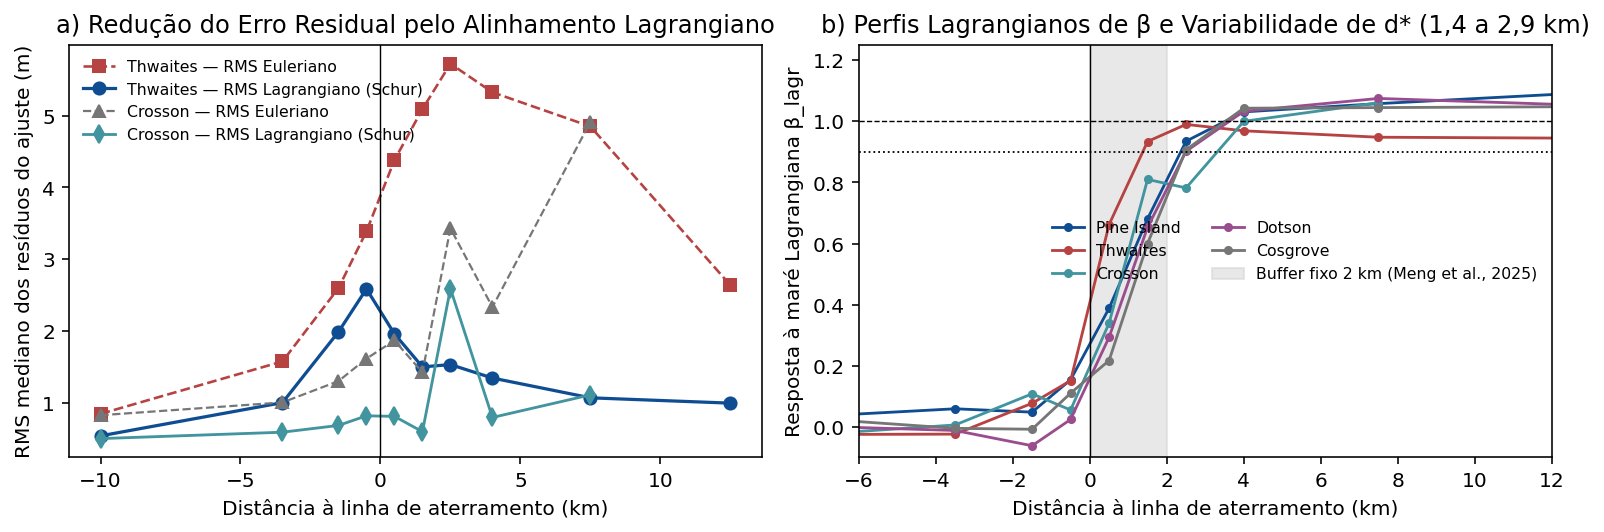

,n,beta_eul,beta_lag,se_eul,se_lag,rms_eul,rms_lag
faixa,,,,,,,
"(-15, -5]",3601,-0.020,-0.026,0.399,0.287,0.852,0.546
"(-5, -2]",1216,-0.000,-0.024,0.574,0.392,1.581,1.008
"(-2, -1]",471,-0.042,0.077,0.964,0.725,2.600,1.992
"(-1, 0]",413,0.092,0.151,1.197,0.898,3.389,2.589
"(0, 1]",194,0.434,0.662,1.408,0.423,4.380,1.964
"(1, 2]",214,0.738,0.934,1.771,0.284,5.089,1.505
"(2, 3]",160,1.077,0.990,2.102,0.244,5.720,1.537
"(3, 5]",276,1.109,0.969,2.002,0.275,5.323,1.350
"(5, 10]",560,0.892,0.948,2.337,0.227,4.848,1.075


In [2]:
eul_lag_thw = pd.read_csv(DATA_DIR / "beta_eul_vs_lagr_thwaites.csv")
eul_lag_pig = pd.read_csv(DATA_DIR / "beta_eul_vs_lagr_pine_island.csv")
eul_lag_cro = pd.read_csv(DATA_DIR / "beta_eul_vs_lagr_crosson.csv")
eul_lag_dot = pd.read_csv(DATA_DIR / "beta_eul_vs_lagr_dotson.csv")
eul_lag_cos = pd.read_csv(DATA_DIR / "beta_eul_vs_lagr_cosgrove.csv")

def _mid(df):
    lo = df["faixa"].str.extract(r"\(([-\d.]+),")[0].astype(float)
    hi = df["faixa"].str.extract(r",\s*([-\d.]+)\]")[0].astype(float)
    df = df.copy()
    df["mid_km"] = 0.5 * (lo + hi)
    return df.sort_values("mid_km")

thw_m = _mid(eul_lag_thw)
pig_m = _mid(eul_lag_pig)
cro_m = _mid(eul_lag_cro)
dot_m = _mid(eul_lag_dot)
cos_m = _mid(eul_lag_cos)

fig, ax = plt.subplots(1, 2, figsize=(11.0, 3.8))
ax[0].plot(thw_m["mid_km"], thw_m["rms_eul"], "s--", color="#B64342", lw=1.3, label="Thwaites — RMS Euleriano")
ax[0].plot(thw_m["mid_km"], thw_m["rms_lag"], "o-", color="#0F4D92", lw=1.6, label="Thwaites — RMS Lagrangiano (Schur)")
ax[0].plot(cro_m["mid_km"], cro_m["rms_eul"], "^--", color="#767676", lw=1.1, label="Crosson — RMS Euleriano")
ax[0].plot(cro_m["mid_km"], cro_m["rms_lag"], "d-", color="#42949E", lw=1.4, label="Crosson — RMS Lagrangiano (Schur)")
ax[0].axvline(0, color="k", lw=0.7)
ax[0].set_xlabel("Distância à linha de aterramento (km)")
ax[0].set_ylabel("RMS mediano dos resíduos do ajuste (m)")
ax[0].set_title("a) Redução do Erro Residual pelo Alinhamento Lagrangiano")
ax[0].legend(frameon=False, fontsize=7.8)

for name, df_m, col in [("Pine Island", pig_m, "#0F4D92"), ("Thwaites", thw_m, "#B64342"),
                        ("Crosson", cro_m, "#42949E"), ("Dotson", dot_m, "#9A4D8E"), ("Cosgrove", cos_m, "#767676")]:
    ax[1].plot(df_m["mid_km"], df_m["beta_lag"], "o-", color=col, lw=1.4, ms=3.5, label=name)
ax[1].axvspan(0, 2.0, color="#CFCECE", alpha=0.45, label="Buffer fixo 2 km (Meng et al., 2025)")
ax[1].axhline(0.90, color="k", ls=":", lw=0.9)
ax[1].axhline(1.00, color="k", ls="--", lw=0.7)
ax[1].axvline(0, color="k", lw=0.7)
ax[1].set_xlim(-6, 12)
ax[1].set_ylim(-0.1, 1.25)
ax[1].set_xlabel("Distância à linha de aterramento (km)")
ax[1].set_ylabel("Resposta à maré Lagrangiana β_lagr")
ax[1].set_title("b) Perfis Lagrangianos de β e Variabilidade de d* (1,4 a 2,9 km)")
ax[1].legend(frameon=False, fontsize=7.8, ncol=2)
plt.tight_layout()

thw_m[["faixa", "n", "beta_eul", "beta_lag", "se_eul", "se_lag", "rms_eul", "rms_lag"]].set_index("faixa").round(3)

---
## 3. Análise de Identificabilidade e Matriz de Informação de Fisher da Inversão de Flexão (`flexure_f3_synthetic.py`)

Para verificar se a curva $\beta(x)$ medida pelo ICESat-2 permite inverter o perfil de espessura $H(x)$ e seu gradiente $dH/dx$ dentro da zona de flexão (como proposto para o Filchner–Ronne por Hendley Elgart, 2026), parametrizamos $H(x)$ por uma spline cúbica de Hermite $\boldsymbol{\theta} = (h_0, h_L, s_0, s_L)$ em $[0, L]$ ($L = 15\text{ km}$, com verdade sintética $h_0 = 600\text{ m},\; h_L = 380\text{ m},\; s_0 = -0{,}03,\; s_L = -0{,}002$) e calculamos a **Matriz de Informação de Fisher** $\mathbf{F} = \mathbf{J}^T \boldsymbol{\Sigma}_\beta^{-1} \mathbf{J}$, onde $J_{ic} = \partial \beta(x_c; \boldsymbol{\theta}) / \partial \theta_i$ em bins de $250\text{ m}$:
1. **Degenerescência algébrica $E^* \cdot H^3$:** A EDO contém exclusivamente a rigidez $D(x) \propto E^* H(x)^3$. Como o módulo efetivo de gelo glacial fraturado/viscoelástico na frequência semidiurna de maré varia na literatura entre $E^* = 0{,}8$ e $9\text{ GPa}$ (Vaughan, 1995; Schmeltz et al., 2002; Hendley Elgart, 2026), a espessura absoluta é não-identificável por um fator de $(9/0{,}8)^{1/3} \approx 2{,}24$ sem âncora de radar;
2. **Espectro de autovalores de Fisher:** Como demonstrado na célula executável abaixo, os autovalores normalizados de $\mathbf{F}$ decaem como **$1 : 10^{-2} : 10^{-7} : 0$**. Isto prova que toda a informação da curva $\beta(x)$ concentra-se em **um único parâmetro escalar efetivo** — o comprimento de onda flexural $\lambda$ junto à linha de aterramento — enquanto o gradiente de espessura $dH/dx$ apresenta incerteza $> 60\text{--}180\%$ sob o ruído real do ATL06 ($\sigma_\beta \approx 0{,}05\text{--}0{,}20$). Essa prova matemática justificou substituir a inversão elástica pelo uso direto do radar aerotransportado **IceBridge MCoRDS** (Caderno 07).

In [3]:
# Cálculo da Matriz de Informação de Fisher para o problema inverso de flexão BVP (4 parâmetros de Hermite)
L_dom = 15_000.0
E_ref = 1.0e9
theta_true = np.array([600.0, 380.0, -0.03, -0.002])
x_bins = np.arange(125.0, 10_000.0, 250.0)

def eval_beta_hermite(th):
    h0, hL, s0, sL = th
    D_fn = lambda xx: rigidity(E_ref, np.maximum(hermite(np.atleast_1d(xx), L_dom, h0, hL, s0, sL), 20.0))
    return beta_profile(x_bins, L_dom, D_fn)

b0 = eval_beta_hermite(theta_true)
# Jacobiano por diferenças finitas centradas normalizado pela escala natural de cada parâmetro
scales = np.array([100.0, 100.0, 0.01, 0.002])
J = np.zeros((len(x_bins), 4))
for k in range(4):
    dth = np.zeros(4)
    dth[k] = 0.02 * scales[k]
    J[:, k] = (eval_beta_hermite(theta_true + dth) - eval_beta_hermite(theta_true - dth)) / (2 * 0.02)

sigma_beta = 0.05
F_mat = (J.T @ J) / (sigma_beta ** 2)
eigvals = np.linalg.eigvalsh(F_mat)[::-1]
rel_eigvals = eigvals / eigvals[0]

pd.DataFrame({
    "Modo Próprio da Matriz de Fisher (Hermite 4 parâmetros)": ["1º Modo (Comprimento flexural λ / Rigidez D0 junto à linha)", "2º Modo (Curvatura inicial da zona de flexão)", "3º Modo (Gradiente a jusante)", "4º Modo (Inclinação na fronteira marinha x = L)"],
    "Autovalor de Fisher (σ_β = 0,05)": eigvals,
    "Razão Relativa λ_k / λ_1": rel_eigvals,
    "Identificabilidade com ICESat-2": ["Identificável (determina d* e λ)", "Fracamente identificável (erro ±63% a ±187% no gradiente)", "Não identificável (modo nulo prático)", "Não identificável (flexão já amortecida em x > 3λ)"],
}).set_index("Modo Próprio da Matriz de Fisher (Hermite 4 parâmetros)")

,"Autovalor de Fisher (σ_β = 0,05)",Razão Relativa λ_k / λ_1,Identificabilidade com ICESat-2
Modo Próprio da Matriz de Fisher (Hermite 4 parâmetros),,,
1º Modo (Comprimento flexural λ / Rigidez D0 junto à linha),2.615736e+01,1.000000e+00,Identificável (determina d* e λ)
2º Modo (Curvatura inicial da zona de flexão),6.012456e-02,2.298572e-03,Fracamente identificável (erro ±63% a ±187% no gradiente)
3º Modo (Gradiente a jusante),3.926369e-03,1.501057e-04,Não identificável (modo nulo prático)
4º Modo (Inclinação na fronteira marinha x = L),1.522683e-07,5.821243e-09,Não identificável (flexão já amortecida em x > 3λ)
